# Drug Discovery Agent on Kaggle — Orchestrator + Fine-Tuned Generator

An autonomous ReAct agent that uses a **fine-tuned EGFR-targeted SMILES generator** as a tool, validates molecules with RDKit, and ranks them by drug-likeness.

**Architecture:**
```
Orchestrator: qwen2.5:7b via Ollama  (reliable native tool-calling)
    |
ReAct loop (LangGraph create_react_agent)
    +-- Tool: generate_candidates -> your fine-tuned Qwen2.5-3B + RDKit validation
    +-- Tool: analyze_and_rank    -> drug-likeness properties + QED ranking
```

**Why this design:**
- **Ollama orchestrator** — native tool-calling is rock-solid, unlike `ChatHuggingFace` which makes small models write tool calls as text. This is the single biggest reliability win.
- **Combined tools** — each tool does a full sub-pipeline in code. Small models reliably skip the second step of granular multi-tool workflows, so we fuse generate+validate and properties+rank+filter.
- **HF generator** — your fine-tuned LoRA runs in transformers; the tool function bridges it to the Ollama agent.

**Setup:**
1. Accelerator: `GPU T4 x2`
2. Internet: `On`
3. Add your fine-tuned adapter as an input dataset

**Memory plan (2× T4, 30 GB):**
- Ollama qwen2.5:7b: ~5 GB
- HF generator (4-bit): ~2 GB

## 1. Install Ollama and start the server

In [1]:
# Install zstd (needed by the Ollama installer)
!apt-get install -y zstd 2>/dev/null || pip install zstandard

# Now install Ollama
!curl -fsSL https://ollama.com/install.sh | sh

import subprocess, time, os
os.environ['OLLAMA_HOST'] = '127.0.0.1:11434'
subprocess.Popen(['ollama', 'serve'])
time.sleep(8)
print('Ollama server started')

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 141 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 0s (9,686 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 125128 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current

time=2026-06-15T15:08:01.845Z level=INFO source=routes.go:1919 msg="server config" env="map[CUDA_VISIBLE_DEVICES: GGML_VK_VISIBLE_DEVICES: GPU_DEVICE_ORDINAL: HIP_VISIBLE_DEVICES: HSA_OVERRIDE_GFX_VERSION: HTTPS_PROXY: HTTP_PROXY: LLAMA_ARG_FIT: LLAMA_ARG_FIT_TARGET: NO_PROXY: OLLAMA_CONTEXT_LENGTH:0 OLLAMA_DEBUG:INFO OLLAMA_DEBUG_LOG_REQUESTS:false OLLAMA_EDITOR: OLLAMA_FLASH_ATTENTION:false OLLAMA_GO_TEMPLATE:true OLLAMA_GPU_OVERHEAD:0 OLLAMA_HOST:http://127.0.0.1:11434 OLLAMA_IGPU_ENABLE: OLLAMA_KEEP_ALIVE:5m0s OLLAMA_KV_CACHE_TYPE: OLLAMA_LLM_LIBRARY: OLLAMA_LOAD_TIMEOUT:5m0s OLLAMA_MAX_LOADED_MODELS:0 OLLAMA_MAX_QUEUE:512 OLLAMA_MAX_TRANSFER_STREAMS:4 OLLAMA_MODELS:/root/.ollama/models OLLAMA_NOHISTORY:false OLLAMA_NOPRUNE:false OLLAMA_NO_CLOUD:false OLLAMA_NUM_PARALLEL:1 OLLAMA_ORIGINS:[http://localhost https://localhost http://localhost:* https://localhost:* http://127.0.0.1 https://127.0.0.1 http://127.0.0.1:* https://127.0.0.1:* http://0.0.0.0 https://0.0.0.0 http://0.0.0.0:* 

Ollama server started


In [2]:
# Pull the orchestrator model (qwen2.5:7b has strong tool-calling)
!ollama pull qwen2.5:7b
print('Orchestrator model ready')

]11;?\[GIN] 2026/06/15 - 15:08:14 | 200 |      89.489µs |       127.0.0.1 | HEAD     "/"
pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ 

time=2026-06-15T15:08:16.171Z level=INFO source=download.go:179 msg="downloading 2bada8a74506 in 16 292 MB part(s)"


pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest 
pulling 2bada8a74506:   0% ▕                  ▏ 147 KB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  55 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   3% ▕                  ▏ 143 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   4% ▕                  ▏ 191 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   6% ▕█                 ▏ 282 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   8% ▕█                 ▏ 378 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   9% ▕█                 ▏ 429 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  11% ▕█                 ▏ 516 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  13% ▕██                ▏ 610 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  14% ▕██   

time=2026-06-15T15:08:34.749Z level=INFO source=download.go:179 msg="downloading 66b9ea09bd5b in 1 68 B part(s)"


pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB         

...

pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████

time=2026-06-15T15:08:37.861Z level=INFO source=download.go:179 msg="downloading 832dd9e00a68 in 1 11 KB part(s)"


pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5

time=2026-06-15T15:08:39.443Z level=INFO source=download.go:179 msg="downloading 2f15b3218f05 in 1 487 B part(s)"


pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 832dd9e00a68: 100% ▕██████████████████▏  11 KB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 832dd9e00a68: 100% ▕██████████████████▏  11 KB                         pulling manifest 
pulling 2bada8a74506: 100% ▕██████████████████▏ 4.7 GB                         
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 832dd9e00a68: 100% ▕██████████████████▏  11 KB              

In [3]:
import subprocess, requests

# Is ollama serve running?
result = subprocess.run(['pgrep', '-f', 'ollama serve'], capture_output=True, text=True)
print("Ollama serve PID:", result.stdout.strip() or "NOT RUNNING")

# Can we reach the API?
try:
    r = requests.get('http://127.0.0.1:11434/api/tags', timeout=5)
    print("API reachable:", r.status_code)
    print("Models:", [m['name'] for m in r.json().get('models', [])])
except Exception as e:
    print("API NOT reachable:", e)

Ollama serve PID: 183
[GIN] 2026/06/15 - 15:08:55 | 200 |     374.902µs |       127.0.0.1 | GET      "/api/tags"
API reachable: 200
Models: ['qwen2.5:7b']


## 2. Install Python dependencies

In [4]:
!pip install -q --upgrade 'transformers>=4.45,<4.57' 'huggingface_hub<1.0'
!pip install -q 'accelerate>=1.0' 'peft>=0.13' 'bitsandbytes>=0.44'
!pip install -q -U 'torchao>=0.16.0'
!pip install -q rdkit
!pip install -q langchain langchain-core langchain-ollama langgraph
print('Dependencies installed. If transformers/bitsandbytes were upgraded, RESTART KERNEL,')
print('then re-run from cell 1 (Ollama install is idempotent).')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 53.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 22.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 29.7 MB/s eta 0:00:0000:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba

## 3. Imports and logging

In [5]:
from __future__ import annotations

import csv
import json
import logging
import re
import sys
import time
from pathlib import Path
from typing import Any

import torch
from langchain_core.tools import tool
from langchain_ollama import ChatOllama
from langgraph.prebuilt import create_react_agent
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, QED, Crippen, Lipinski
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.logger().setLevel(RDLogger.WARNING)

if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)-7s | %(message)s',
    datefmt='%H:%M:%S',
    stream=sys.stdout,
)
logger = logging.getLogger(__name__)
logging.getLogger('httpx').setLevel(logging.WARNING)
print('Logging configured')

Logging configured


## 4. Configuration

In [10]:
# ─── Generator (your fine-tuned model) ───
GENERATOR_BASE = 'Qwen/Qwen2.5-3B'
GENERATOR_ADAPTER = '/kaggle/input/datasets/aleksandrapacult/qwen25-3b-smiles-egfr-lora-3'   # ← EGFR-targeted adapter
GEN_PROMPT_PREFIX = 'Generate a drug-like molecule active against EGFR: '

# ─── Orchestrator (Ollama) ───
ORCHESTRATOR_MODEL = 'qwen2.5:7b'
ORCHESTRATOR_TEMPERATURE = 0.3 

# ─── Output ───
CSV_PATH: Path = Path.cwd() / 'agent_candidates.csv'
CSV_HEADERS = ['timestamp', 'smiles', 'MW', 'logP', 'TPSA', 'QED', 'HBD', 'HBA', 'lipinski_violations']

print('Generator:', GENERATOR_BASE, '+ adapter')
print('Orchestrator:', ORCHESTRATOR_MODEL)
print('Results CSV:', CSV_PATH)

Generator: Qwen/Qwen2.5-3B + adapter
Orchestrator: qwen2.5:7b
Results CSV: /kaggle/working/agent_candidates.csv


## 5. Load the fine-tuned SMILES generator (HF transformers, GPU 1)

In [11]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

bnb = BitsAndBytesConfig(
    load_in_4bit=True, bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
)

logger.info('Loading generator on GPU 1...')
gen_tokenizer = AutoTokenizer.from_pretrained(GENERATOR_BASE, trust_remote_code=True)
if gen_tokenizer.pad_token is None:
    gen_tokenizer.pad_token = gen_tokenizer.eos_token

_gen_base = AutoModelForCausalLM.from_pretrained(
    GENERATOR_BASE, quantization_config=bnb,
    device_map={'': 1}, trust_remote_code=True, torch_dtype=torch.float16,
)
generator = PeftModel.from_pretrained(_gen_base, GENERATOR_ADAPTER)
generator.eval()
logger.info('Generator ready on GPU 1')

15:15:11 | INFO    | Loading generator on GPU 1...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/peft/config.py:220: UserWarning: Unexpected keyword arguments ['lora_ga_config', 'use_bdlora'] for class LoraConfig, these are ignored. This probably means that you're loading a configuration file that was saved using a higher version of the library and additional parameters have been introduced since. It is highly recommended to upgrade the PEFT version before continuing (e.g. by running `pip install -U peft`).
  warnings.warn(


15:15:23 | INFO    | Generator ready on GPU 1


## 6. Core generation function

Calls the fine-tuned model and returns raw SMILES strings. The leading-character cleanup handles the tokenizer boundary quirk.

In [12]:
def _clean_smiles(text: str) -> str:
    """Strip leading non-atom characters (digits etc.) that aren't valid SMILES starts."""
    text = text.strip().split('\n')[0].strip()
    m = re.search(r'[A-Za-z\[]', text)
    return text[m.start():] if m else text

def generate_raw_smiles(n: int = 10, temperature: float = 0.8) -> list[str]:
    """Generate n SMILES strings using the fine-tuned model (token-slice extraction)."""
    n = min(int(n), 50)
    inputs = gen_tokenizer([GEN_PROMPT_PREFIX] * n, return_tensors='pt', padding=True).to(generator.device)
    L = inputs['input_ids'].shape[1]
    with torch.no_grad():
        out = generator.generate(
            **inputs, max_new_tokens=100, do_sample=True,
            temperature=temperature, top_p=0.95,
            pad_token_id=gen_tokenizer.eos_token_id,
        )
    smiles = [_clean_smiles(gen_tokenizer.decode(o[L:], skip_special_tokens=True)) for o in out]
    torch.cuda.empty_cache()
    return smiles

# Smoke test
logger.info('Testing generator...')
test = generate_raw_smiles(n=5)
for s in test:
    mol = Chem.MolFromSmiles(s)
    logger.info('  [%s] %s', '+' if mol else '-', s)

15:15:52 | INFO    | Testing generator...
15:16:03 | INFO    |   [-] c2ccc(Oc3ccccc3)cc2c2c[nH]nc21
15:16:03 | INFO    |   [+] Nc2ncnc(Nc3cccc(Oc4ccccc4)c3)c2Nc1ccccc1
15:16:03 | INFO    |   [+] CCN(C(=O)C2CCN(CCS(C)(=O)=O)CC2)c2ncnc(Nc3ccc(OCc4cccc(F)c4)c(Cl)c3)c2
15:16:03 | INFO    |   [+] CCC(=O)N1CC[C@H](N2C(=O)N(c3ccc(F)cc3)Cc3cnc(Nc4ccc(N5CCN(C)CC5)c(C)c4)nc32)C1
15:16:03 | INFO    |   [+] Nc2ncnc(Nc3cccc(C(F)(F)F)c3)c2Nc1cccc(C(F)(F)F)c1


[15:16:03] SMILES Parse Error: unclosed ring for input: 'c2ccc(Oc3ccccc3)cc2c2c[nH]nc21'


## 7. CSV persistence

In [13]:
def _load_discovered() -> set[str]:
    if not CSV_PATH.exists():
        return set()
    try:
        with open(CSV_PATH, newline='', encoding='utf-8') as fh:
            return {row['smiles'] for row in csv.DictReader(fh) if row.get('smiles')}
    except OSError as exc:
        logger.warning('[CSV] Could not read: %s', exc)
        return set()

discovered_smiles: set[str] = _load_discovered()

def save_to_csv(props: dict[str, Any]) -> None:
    """Append a candidate's properties to the CSV (creates with headers if new)."""
    file_exists = CSV_PATH.exists() and CSV_PATH.stat().st_size > 0
    try:
        with open(CSV_PATH, 'a', newline='', encoding='utf-8') as fh:
            writer = csv.writer(fh)
            if not file_exists:
                writer.writerow(CSV_HEADERS)
            writer.writerow([
                time.strftime('%Y-%m-%d %H:%M:%S'),
                props['smiles'], props['MW'], props['logP'], props['TPSA'],
                props['QED'], props['HBD'], props['HBA'], props['lipinski_violations'],
            ])
        discovered_smiles.add(props['smiles'])
    except OSError as exc:
        logger.error('[CSV] Failed to write: %s', exc)

print(f'Loaded {len(discovered_smiles)} previously saved candidates')

Loaded 0 previously saved candidates


## 8. Drug-likeness property helper

In [14]:
def compute_props(smiles: str) -> dict[str, Any]:
    """Compute drug-likeness properties for a single SMILES."""
    mol = Chem.MolFromSmiles(smiles) if smiles else None
    if mol is None or mol.GetNumAtoms() == 0:
        return {'smiles': smiles, 'valid': False}
    return {
        'smiles': Chem.MolToSmiles(mol),
        'valid': True,
        'MW': round(Descriptors.MolWt(mol), 1),
        'logP': round(Crippen.MolLogP(mol), 2),
        'TPSA': round(Descriptors.TPSA(mol), 1),
        'HBD': Lipinski.NumHDonors(mol),
        'HBA': Lipinski.NumHAcceptors(mol),
        'QED': round(QED.qed(mol), 3),
        'lipinski_violations': sum([
            Descriptors.MolWt(mol) > 500,
            Crippen.MolLogP(mol) > 5,
            Lipinski.NumHDonors(mol) > 5,
            Lipinski.NumHAcceptors(mol) > 10,
        ]),
    }

## 9. The combined agent tools

Following the single-combined-tool philosophy: each tool runs a full sub-pipeline in code so the orchestrator can't skip steps.

- `generate_candidates(n)` → generates via the fine-tuned model **and** validates with RDKit, returning only valid canonical SMILES.
- `analyze_and_rank(smiles_json, top_k)` → computes properties, filters Lipinski-compliant, ranks by QED, saves to CSV, returns the best.

The orchestrator cannot invent molecules — `generate_candidates` is the ONLY source.

In [15]:
# ─────────────────────────────────────────────────────────────────────────
# AGENTIC TOOLS (Option B: code computes metrics, the LLM makes decisions)
#
# Key fix vs the first version: the agent NO LONGER has to hand the SMILES list
# from one tool to the next. generate_candidates stashes its result in code
# (_last_generation), and analyze_and_rank / edit_molecule fall back to that
# stash when the agent doesn't pass clean input. This removes the JSON-passing
# step that the 7B orchestrator kept botching (it looped on analyze_and_rank
# 9 times trying to "fix the format"). Metrics still come back so the agent can
# steer temperature.
# ─────────────────────────────────────────────────────────────────────────

# Whole-session memory of what the generator has produced (for duplicate_ratio).
_session_seen: set[str] = set()
# The molecules from the MOST RECENT generate_candidates call. analyze_and_rank
# and edit_molecule use this automatically so the agent doesn't have to relay it.
_last_generation: list[str] = []


def _coerce_smiles_input(smiles_json: str) -> tuple[list[str], str]:
    """Best-effort extraction of a SMILES list from whatever the agent passed.
    Returns (smiles_list, note). Falls back to the last generation if the input
    is empty/unparseable, instead of silently returning nothing."""
    candidates: list[str] = []
    note = ''
    if smiles_json and str(smiles_json).strip():
        try:
            parsed = json.loads(smiles_json)
            if isinstance(parsed, dict):
                candidates = parsed.get('smiles', []) or []
            elif isinstance(parsed, list):
                candidates = parsed
            elif isinstance(parsed, str) and Chem.MolFromSmiles(parsed):
                candidates = [parsed]
        except (json.JSONDecodeError, TypeError):
            if isinstance(smiles_json, str) and Chem.MolFromSmiles(smiles_json):
                candidates = [smiles_json]
    # keep only things that actually parse
    candidates = [s for s in candidates if isinstance(s, str) and Chem.MolFromSmiles(s)]
    if not candidates:
        candidates = list(_last_generation)
        note = ('input was empty/invalid, so I used the molecules from the most '
                'recent generate_candidates call')
    return candidates, note


def _slim_molecule(smiles: str, max_variants: int = 6) -> dict[str, Any]:
    """Plain helper (not a tool): propose lighter, valid variants of a heavy molecule.

    Strategy = MINIMAL CHANGE. Instead of collapsing to the bare scaffold (which throws
    away the pharmacophore — e.g. the bromo-aniline that matters for EGFR binding), we
    break ONE BRICS bond at a time and keep the LARGEST remaining piece. That trims a
    single peripheral group while preserving most of the molecule. The Murcko scaffold is
    kept only as a last-resort fallback. Variants are ranked by Lipinski-compliance, then
    QED, so we pick the best-quality compliant variant that stays closest to the original.
    """
    from rdkit.Chem import BRICS
    from rdkit.Chem.Scaffolds import MurckoScaffold
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {'error': 'invalid SMILES', 'original': None, 'variants': []}
    orig_mw = round(Descriptors.MolWt(mol), 1)
    variants: list[dict[str, Any]] = []
    seen: set[str] = {Chem.MolToSmiles(mol)}

    # ── Minimal change: remove one fragment at a time, keep the largest remainder ──
    try:
        for (a1, a2), _ in BRICS.FindBRICSBonds(mol):
            bond = mol.GetBondBetweenAtoms(a1, a2)
            if bond is None:
                continue
            try:
                frag_mol = Chem.FragmentOnBonds(mol, [bond.GetIdx()], addDummies=False)
                pieces = Chem.GetMolFrags(frag_mol, asMols=True, sanitizeFrags=False)
            except Exception:
                continue
            if len(pieces) < 2:
                continue
            biggest = max(pieces, key=lambda m: m.GetNumAtoms())
            if biggest.GetNumAtoms() < 4:
                continue
            try:
                Chem.SanitizeMol(biggest)
                cs = Chem.MolToSmiles(biggest)
            except Exception:
                continue
            if cs in seen:
                continue
            seen.add(cs)
            p = compute_props(cs)
            if p.get('valid') and p['MW'] < orig_mw:
                variants.append({'smiles': cs, 'MW': p['MW'], 'QED': p['QED'],
                                 'lipinski_violations': p['lipinski_violations'], 'change': 'remove_one_fragment'})
    except Exception as exc:
        logger.warning('[slim] fragment removal failed: %s', exc)

    # ── Last-resort fallback: bare Murcko scaffold ──
    try:
        scaf = MurckoScaffold.GetScaffoldForMol(mol)
        if scaf is not None and scaf.GetNumAtoms() > 0:
            cs = Chem.MolToSmiles(scaf)
            if cs not in seen:
                seen.add(cs)
                p = compute_props(cs)
                if p.get('valid'):
                    variants.append({'smiles': cs, 'MW': p['MW'], 'QED': p['QED'],
                                     'lipinski_violations': p['lipinski_violations'], 'change': 'murcko_scaffold'})
    except Exception as exc:
        logger.warning('[slim] scaffold failed: %s', exc)

    # Rank: compliant first, then best QED. This favours a high-quality compliant variant
    # that keeps the pharmacophore over an aggressively stripped skeleton.
    variants.sort(key=lambda v: (v['lipinski_violations'], -v['QED']))
    return {'original': {'smiles': Chem.MolToSmiles(mol), 'MW': orig_mw}, 'variants': variants[:max_variants]}


@tool
def generate_candidates(n: int = 10, temperature: float = 0.8) -> str:
    """Generate drug-like molecules with the fine-tuned generator and validate them.
    This is the ONLY source of molecules. After calling this, just call analyze_and_rank
    with NO arguments (or {}) — it automatically uses the molecules generated here. You
    do NOT need to copy the SMILES list yourself.

    Use `temperature` to steer the generator on the NEXT call:
      - RAISE it (1.0–1.3) if the previous call reported a high duplicate_ratio (>0.3).
      - LOWER it (0.4–0.6) if the previous call reported a low validity_rate (<0.7).

    Args:
        n: how many to attempt (max 50).
        temperature: 0.3–1.5, default 0.8.

    Returns JSON: n_valid, n_new, validity_rate, duplicate_ratio, temperature_used.
    (The molecule list is stored internally for analyze_and_rank — not your concern.)
    """
    global _last_generation
    temperature = float(max(0.3, min(1.5, temperature)))

    # Thresholds for what counts as a 'bad' generation.
    DUP_HI, VAL_LO = 0.3, 0.7  # tightened: react to real generator degradation, not just collapse

    def _attempt(temp: float) -> dict[str, Any]:
        """One generation pass. Stashes molecules and returns its own metrics."""
        global _last_generation
        logger.info('[Tool:generate_candidates] n=%d temperature=%.2f', n, temp)
        raw = generate_raw_smiles(n=n, temperature=temp)
        valid_canon = [p['smiles'] for p in (compute_props(s) for s in raw) if p.get('valid')]
        valid_unique = list(dict.fromkeys(valid_canon))
        new_mols = [s for s in valid_unique if s not in _session_seen]
        n_dup = len(valid_unique) - len(new_mols)
        _session_seen.update(valid_unique)
        _last_generation = new_mols if new_mols else valid_unique
        vr = round(len(valid_canon) / len(raw), 3) if raw else 0.0
        dr = round(n_dup / len(valid_unique), 3) if valid_unique else 0.0
        logger.info('[Tool:generate_candidates] valid=%d new=%d | validity_rate=%.2f duplicate_ratio=%.2f',
                    len(valid_unique), len(new_mols), vr, dr)
        return {'n_valid': len(valid_unique), 'n_new': len(new_mols),
                'validity_rate': vr, 'duplicate_ratio': dr, 'temperature_used': temp}

    # First attempt
    first = _attempt(temperature)

    # Code-guaranteed adaptive retry (Path 1.5): if metrics are bad, the CODE retries once
    # with a corrected temperature so the feedback loop ALWAYS closes -- we do not rely on
    # the 7B model to remember to do it. The agent still sees the metrics and explains them.
    retry = None
    reason = None
    new_temp = temperature
    if first['duplicate_ratio'] > DUP_HI:
        reason = f"duplicate_ratio {first['duplicate_ratio']} > {DUP_HI} (generator repeating)"
        new_temp = min(1.5, temperature + 0.3)
    elif first['validity_rate'] < VAL_LO:
        reason = f"validity_rate {first['validity_rate']} < {VAL_LO} (too random)"
        new_temp = max(0.3, temperature - 0.2)
    if reason is not None and abs(new_temp - temperature) > 1e-6:
        logger.info('[Tool:generate_candidates] AUTO-RETRY: %s -> temperature %.2f', reason, new_temp)
        retry = _attempt(new_temp)

    final = retry if retry is not None else first
    result = dict(final)
    result['note'] = 'Molecules stored. Call analyze_and_rank() with no SMILES argument to score them.'
    if retry is not None:
        result['auto_retry'] = {'reason': reason, 'first_attempt': first,
                                'retried_at_temperature': final['temperature_used']}
        result['note'] += (f" NOTE: first attempt was weak ({reason}); the system automatically "
                           f"re-generated at temperature {final['temperature_used']}. Stored molecules are from the retry.")
    return json.dumps(result)


@tool
def analyze_and_rank(smiles_json: str = '', top_k: int = 5) -> str:
    """Score the molecules from the most recent generate_candidates call: compute
    drug-likeness (MW, logP, TPSA, QED, Lipinski), keep Lipinski-compliant ones, save
    ALL of them, rank by QED, and return the top_k.

    You normally call this with NO arguments right after generate_candidates — it uses
    the freshly generated molecules automatically. Only pass smiles_json if you want to
    score a SPECIFIC custom list (e.g. variants returned by edit_molecule).

    Molecules that are good but fail ONLY on weight (MW > 500) are flagged as `too_heavy`
    so you can pass them to edit_molecule.

    Args:
        smiles_json: optional JSON array of SMILES. Leave empty to use the last generation.
        top_k: how many top candidates to return.

    Returns JSON: top, n_compliant_saved, too_heavy, note.
    """
    MIN_QED_TO_SAVE = 0.5  # only persist genuinely drug-like hits; weak ones still shown but not saved
    smiles_list, note = _coerce_smiles_input(smiles_json)
    logger.info('[Tool:analyze_and_rank] analyzing %d molecules%s',
                len(smiles_list), f' ({note})' if note else '')

    if not smiles_list:
        return json.dumps({'top': [], 'n_compliant_saved': 0, 'too_heavy': [],
                           'note': 'No molecules available. Call generate_candidates first.'})

    compliant: list[dict[str, Any]] = []
    too_heavy: list[dict[str, Any]] = []
    for smi in smiles_list:
        props = compute_props(smi)
        if not props.get('valid'):
            continue
        if props['lipinski_violations'] == 0:
            compliant.append(props)
        elif props['MW'] > 500 and props['QED'] >= 0.4:
            too_heavy.append({'smiles': props['smiles'], 'MW': props['MW'], 'QED': props['QED']})

    # ── Code-guaranteed auto-editing (Path 1.5) ──
    # For each good-but-too-heavy molecule, the CODE slims it down and, if a lighter
    # Lipinski-compliant variant exists, adds it to the candidate pool. We do NOT rely on
    # the 7B model to remember to call edit_molecule — the feedback loop always closes.
    auto_edits: list[dict[str, Any]] = []
    for heavy in too_heavy:
        slim = _slim_molecule(heavy['smiles'])
        best = next((v for v in slim['variants'] if v['lipinski_violations'] == 0), None)
        if best is not None:
            fixed = compute_props(best['smiles'])
            if fixed.get('valid') and fixed['lipinski_violations'] == 0:
                compliant.append(fixed)
                auto_edits.append({'from': heavy['smiles'], 'from_MW': heavy['MW'],
                                   'to': fixed['smiles'], 'to_MW': fixed['MW'],
                                   'to_QED': fixed['QED'], 'change': best['change']})
                logger.info('[Tool:analyze_and_rank] AUTO-EDIT: %s (MW=%.1f) -> %s (MW=%.1f, QED=%.3f)',
                            heavy['smiles'], heavy['MW'], fixed['smiles'], fixed['MW'], fixed['QED'])

    compliant.sort(key=lambda x: x['QED'], reverse=True)
    # Persist only hits above the QED bar (keeps the CSV meaningful); weaker compliant
    # molecules are still returned to the agent for the ranking but not saved.
    n_saved = 0
    for p in compliant:
        if p['QED'] >= MIN_QED_TO_SAVE and p['smiles'] not in discovered_smiles:
            save_to_csv(p)
            n_saved += 1

    top = compliant[:int(top_k)]
    logger.info('[Tool:analyze_and_rank] %d compliant (%d saved, QED>=%.1f), %d too-heavy, %d auto-edited',
                len(compliant), n_saved, MIN_QED_TO_SAVE, len(too_heavy), len(auto_edits))
    for i, p in enumerate(top, 1):
        logger.info('  %d. QED=%.3f MW=%.1f  %s', i, p['QED'], p['MW'], p['smiles'])

    out = {'top': top, 'n_compliant': len(compliant), 'n_saved': n_saved,
           'min_qed_to_save': MIN_QED_TO_SAVE, 'too_heavy': too_heavy}
    if auto_edits:
        out['auto_edits'] = auto_edits
        extra = (f' NOTE: {len(auto_edits)} too-heavy molecule(s) were automatically slimmed '
                 f'down to Lipinski-compliant variants and added to the candidates.')
        out['note'] = (note + extra) if note else extra.strip()
    elif note:
        out['note'] = note
    return json.dumps(out, indent=2)


@tool
def edit_molecule(smiles: str) -> str:
    """Propose lighter, chemically-valid variants of an over-weight molecule (Murcko
    scaffold + BRICS fragments). NOTE: analyze_and_rank already auto-edits too-heavy
    molecules, so you rarely need this. Use it only to inspect alternatives for a
    specific molecule. Returns JSON: original, variants.

    Args:
        smiles: the heavy molecule to slim down.
    """
    result = _slim_molecule(smiles)
    logger.info('[Tool:edit_molecule] %s -> %d variants', smiles, len(result.get('variants', [])))
    return json.dumps(result, indent=2)


print('Tools defined: generate_candidates, analyze_and_rank, edit_molecule')


Tools defined: generate_candidates, analyze_and_rank, edit_molecule


## 10. Orchestrator LLM and ReAct agent

In [16]:
def build_llm() -> ChatOllama:
    """Local Ollama-backed orchestrator with reliable native tool-calling."""
    return ChatOllama(model=ORCHESTRATOR_MODEL, temperature=ORCHESTRATOR_TEMPERATURE)


SYSTEM_PROMPT: str = """\
You are a drug discovery orchestrator working on EGFR inhibitors. The fine-tuned generator
produces molecules designed to be active against EGFR (a key cancer target). You coordinate
three tools and have NO ability to invent or edit molecules yourself — every molecule comes
from a tool.

TOOLS
  1. generate_candidates(n, temperature) — the ONLY source of new molecules. Returns
     feedback metrics (validity_rate, duplicate_ratio). The molecules themselves are
     stored internally; you do NOT receive or relay them.
  2. analyze_and_rank() — scores the molecules from the LAST generate_candidates call.
     CALL IT WITH NO ARGUMENTS. Do not try to pass a SMILES list; it already has them.
  3. edit_molecule(smiles) — proposes lighter variants of a single too-heavy molecule.

WORKFLOW
  Step 1. Call generate_candidates(n=<count>). The tool AUTOMATICALLY retries once at a
          corrected temperature if the first attempt is weak (high duplicate_ratio or low
          validity_rate) -- you do NOT need to call it again yourself. If the result
          contains an `auto_retry` field, the system already handled it; just report in your
          final answer that an automatic temperature adjustment happened and why.
  Step 2. Call analyze_and_rank() with NO arguments. It scores the stored molecules,
          saves the good ones, and may report `too_heavy` molecules.
  Step 3. Too-heavy molecules are handled AUTOMATICALLY: analyze_and_rank slims them down
          and adds compliant variants itself. If the result has an `auto_edits` field,
          just report in your final answer that heavy hits were automatically edited.
          You do NOT need to call edit_molecule yourself.
  Step 4. Present the final answer from the tool outputs: SMILES + properties (MW, logP,
          QED, Lipinski). Briefly note any temperature/edit decisions you made.

CRITICAL RULES
  - After generate_candidates, ALWAYS call analyze_and_rank() with NO SMILES argument.
  - NEVER call analyze_and_rank repeatedly trying to "fix the format". If it returns a
    `note`, read it — it already handled the input. Move on to Step 4.
  - NEVER call generate_candidates a second time to adjust temperature yourself — the tool
    already retries automatically. Calling it again only wastes a round.
  - NEVER call edit_molecule to fix too-heavy molecules — analyze_and_rank already edits
    them automatically. Just report what the `auto_edits` field says.
  - NEVER write or modify a SMILES from your own knowledge.
  - Base every number in your answer on actual tool outputs.
"""


def build_agent() -> Any:
    """Construct the ReAct agent with the three tools and the adaptive system prompt."""
    tools = [generate_candidates, analyze_and_rank, edit_molecule]
    llm = build_llm()
    return create_react_agent(model=llm, tools=tools, prompt=SYSTEM_PROMPT)


agent = build_agent()
print('Agent ready (3 tools, no-relay contract)')


Agent ready (3 tools, no-relay contract)


/tmp/ipykernel_58/1419532910.py:52: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  return create_react_agent(model=llm, tools=tools, prompt=SYSTEM_PROMPT)


## 11. Run a single round

In [17]:
task = (
    'Generate 20 drug-like molecules active against EGFR using the generator. Check the feedback metrics '
    'and adapt the temperature if the generator is repeating itself or producing junk. '
    'Then call analyze_and_rank with no arguments to score them, edit any good-but-too-heavy hits, and give me the 5 most '
    'drug-like EGFR-targeted candidates with their properties.'
)

result = agent.invoke(
    {'messages': [('human', task)]},
    config={'recursion_limit': 50},
)

messages = result.get('messages', [])
if messages:
    final = messages[-1]
    content = final.content if hasattr(final, 'content') else str(final)
    print('\n' + '='*70)
    print('AGENT FINAL ANSWER:')
    print('='*70)
    print(content)

# Verify the generator was actually used
used_generator = any(
    hasattr(m, 'name') and m.name == 'generate_candidates'
    for m in messages
)
tool_names = [m.name for m in messages if hasattr(m, 'name') and m.name]
print('[Verification] Tools called this round:', tool_names)
print('\n[Verification] generate_candidates was called:', used_generator)
if not used_generator:
    print('WARNING: the agent did not call the generator. Check the trace below.')

time=2026-06-15T15:16:38.213Z level=INFO source=sched.go:1014 msg="selecting single GPU for llama-server model" main_gpu=0 id=0 filter_id=0 library=CUDA name=CUDA0 description="Tesla T4" integrated=false predicted="6.1 GiB" available="14.3 GiB"
time=2026-06-15T15:16:38.213Z level=INFO source=sched.go:1133 msg="selecting GPU backend for llama-server model" library=CUDA gpu_count=1 available_gpu_count=2
time=2026-06-15T15:16:38.213Z level=INFO source=server.go:109 msg="using llama-server for model" model=/root/.ollama/models/blobs/sha256-2bada8a7450677000f678be90653b85d364de7db25eb5ea54136ada5f3933730
time=2026-06-15T15:16:38.213Z level=INFO source=llama_server.go:403 msg="starting llama-server" cmd="/usr/local/lib/ollama/llama-server --model /root/.ollama/models/blobs/sha256-2bada8a7450677000f678be90653b85d364de7db25eb5ea54136ada5f3933730 --port 46757 --host 127.0.0.1 --no-webui --offline -c 32768 -np 1 --log-verbosity 4 --no-log-prefix --no-log-timestamps --no-jinja --chat-template cha

15:18:02 | INFO    | [Tool:generate_candidates] n=20 temperature=0.80
[GIN] 2026/06/15 - 15:18:02 | 200 |         1m26s |       127.0.0.1 | POST     "/api/chat"


slot print_timing: id  0 | task 0 | prompt eval time =   41919.75 ms /  1313 tokens (   31.93 ms per token,    31.32 tokens per second)
slot print_timing: id  0 | task 0 |        eval time =    9464.18 ms /    29 tokens (  326.35 ms per token,     3.06 tokens per second)
slot print_timing: id  0 | task 0 |       total time =   51383.93 ms /  1342 tokens
slot print_timing: id  0 | task 0 |    graphs reused =         28
slot      release: id  0 | task 0 | stop processing: n_tokens = 1341, truncated = 0
srv  update_slots: all slots are idle


15:18:11 | INFO    | [Tool:generate_candidates] valid=14 new=14 | validity_rate=0.75 duplicate_ratio=0.00


[15:18:11] SMILES Parse Error: unclosed ring for input: 'CCN(Cc2ccn3ncnc(Nc4ccc5c(cnn5Cc5cccc(F)c5)c4)c23)CC1'
[15:18:11] SMILES Parse Error: unclosed ring for input: 'CCN(Cc2ccn3ncnc(Nc4ccc5c(cnn5Cc5cccc(F)c5)c4)c23)CC1'
[15:18:11] SMILES Parse Error: unclosed ring for input: 'C2CCN(Cc3ccc(Nc4ccncc4)cc3)C(C)(C)C1'
[15:18:11] SMILES Parse Error: unclosed ring for input: 'Oc2cc(Nc3n[nH]c4ccccc34)ccc2Nc2ncc(Cl)c(=O)n21'
[15:18:11] Can't kekulize mol.  Unkekulized atoms: 11 12 13 41 42
srv  log_server_r: done request: POST /tokenize 127.0.0.1 200
slot get_availabl: id  0 | task -1 | selected slot by LCP similarity, sim_best = 0.933 (> 0.100 thold), f_keep = 0.990
slot launch_slot_: id  0 | task -1 | sampler chain: logits -> penalties -> ?dry -> ?top-n-sigma -> top-k -> ?typical -> top-p -> ?min-p -> ?xtc -> temp-ext -> dist 
slot launch_slot_: id  0 | task -1 | sampler params: 
	repeat_last_n = 64, repeat_penalty = 1.100, frequency_penalty = 0.000, presence_penalty = 0.000
	dry_multiplier

[GIN] 2026/06/15 - 15:18:12 | 200 |  918.283555ms |       127.0.0.1 | POST     "/api/chat"
15:18:12 | INFO    | [Tool:analyze_and_rank] analyzing 14 molecules (input was empty/invalid, so I used the molecules from the most recent generate_candidates call)
15:18:12 | INFO    | [Tool:analyze_and_rank] 8 compliant (5 saved, QED>=0.5), 0 too-heavy, 0 auto-edited
15:18:12 | INFO    |   1. QED=0.771 MW=243.3  Cc1cn(C2CCN(S(C)(=O)=O)CC2)cn1
15:18:12 | INFO    |   2. QED=0.763 MW=256.7  Clc1cccc(Nc2ncnc3cnccc23)c1
15:18:12 | INFO    |   3. QED=0.713 MW=286.3  O=[SH](=O)c1ccc(Nc2ncnc3ccncc23)cc1
15:18:12 | INFO    |   4. QED=0.558 MW=347.4  OC[C@@H](Nc1ncnc2sc(-c3ccccc3)cc12)c1ccccc1
15:18:12 | INFO    |   5. QED=0.514 MW=367.2  Oc1nc2ccccc2c2ncnc(Nc3cccc(Br)c3)c12


slot print_timing: id  0 | task 31 | prompt eval time =     158.79 ms /    96 tokens (    1.65 ms per token,   604.58 tokens per second)
slot print_timing: id  0 | task 31 |        eval time =     489.18 ms /    17 tokens (   28.78 ms per token,    34.75 tokens per second)
slot print_timing: id  0 | task 31 |       total time =     647.97 ms /   113 tokens
slot print_timing: id  0 | task 31 |    graphs reused =         43
slot      release: id  0 | task 31 | stop processing: n_tokens = 1440, truncated = 0
srv  update_slots: all slots are idle
srv  log_server_r: done request: POST /tokenize 127.0.0.1 200
slot get_availabl: id  0 | task -1 | selected slot by LCP similarity, sim_best = 0.692 (> 0.100 thold), f_keep = 1.000
slot launch_slot_: id  0 | task -1 | sampler chain: logits -> penalties -> ?dry -> ?top-n-sigma -> top-k -> ?typical -> top-p -> ?min-p -> ?xtc -> temp-ext -> dist 
slot launch_slot_: id  0 | task -1 | sampler params: 
	repeat_last_n = 64, repeat_penalty = 1.100, freque

[GIN] 2026/06/15 - 15:18:31 | 200 | 18.719186221s |       127.0.0.1 | POST     "/api/chat"

AGENT FINAL ANSWER:
Based on the feedback metrics from the initial generation of 20 drug-like molecules using the generator with a temperature of 0.8, we had a validity rate of 75% and no duplicate molecules, which is good. The system did not require an automatic retry as the metrics were within acceptable ranges.

After scoring these molecules, the top five most drug-like EGFR-targeted candidates are:

1. **Molecule 1:**
   - SMILES: `Cc1cn(C2CCN(S(C)(=O)=O)CC2)cn1`
   - Molecular Weight (MW): 243.3
   - LogP: 0.79
   - TPSA: 55.2
   - QED: 0.771

2. **Molecule 2:**
   - SMILES: `Clc1cccc(Nc2ncnc3cnccc23)c1`
   - MW: 256.7
   - LogP: 3.42
   - TPSA: 50.7
   - QED: 0.763

3. **Molecule 3:**
   - SMILES: `O=[SH](=O)c1ccc(Nc2ncnc3ccncc23)cc1`
   - MW: 286.3
   - LogP: 1.74
   - TPSA: 84.8
   - QED: 0.713

4. **Molecule 4:**
   - SMILES: `OC[C@@H](Nc1ncnc2sc(-c3ccccc3)cc12)c1ccccc1`
   - MW: 347.4


slot print_timing: id  0 | task 49 | prompt eval time =     577.85 ms /   641 tokens (    0.90 ms per token,  1109.28 tokens per second)
slot print_timing: id  0 | task 49 |        eval time =   17869.36 ms /   544 tokens (   32.85 ms per token,    30.44 tokens per second)
slot print_timing: id  0 | task 49 |       total time =   18447.21 ms /  1185 tokens
slot print_timing: id  0 | task 49 |    graphs reused =        583
slot      release: id  0 | task 49 | stop processing: n_tokens = 2624, truncated = 0
srv  update_slots: all slots are idle


## 12. Full reasoning trace (optional)

In [19]:
for msg in result['messages']:
    msg.pretty_print()

================================ Human Message =================================

Generate 20 drug-like molecules active against EGFR using the generator. Check the feedback metrics and adapt the temperature if the generator is repeating itself or producing junk. Then call analyze_and_rank with no arguments to score them, edit any good-but-too-heavy hits, and give me the 5 most drug-like EGFR-targeted candidates with their properties.
================================== Ai Message ==================================
Tool Calls:
  generate_candidates (de08db42-bc0f-43cf-aecd-37e580ac9f76)
 Call ID: de08db42-bc0f-43cf-aecd-37e580ac9f76
  Args:
    n: 20
    temperature: 0.8
================================= Tool Message =================================
Name: generate_candidates

{"n_valid": 14, "n_new": 14, "validity_rate": 0.75, "duplicate_ratio": 0.0, "temperature_used": 0.8, "note": "Molecules stored. Call analyze_and_rank() with no SMILES argument to score them."}
====================

## 13. Discovery loop

Run multiple rounds. Each round is a fresh agent invocation. Interrupt the cell to stop early.

In [20]:
def run_discovery(n_rounds: int = 5, n_per_round: int = 20, top_k: int = 5) -> None:
    """Run n_rounds of generate -> analyze -> save. Interrupt the cell to halt."""
    task = (
        f'Generate {n_per_round} drug-like molecules active against EGFR using the generator. Read the feedback '
        f'metrics and adapt temperature if needed (raise it on high duplicate_ratio, lower it '
        f'on low validity_rate). Then call analyze_and_rank with no arguments to score them, edit any good-but-too-heavy hits, and '
        f'give me the {top_k} most drug-like EGFR-targeted candidates with their properties.'
    )
    total_calls = 0
    error_streak = 0

    logger.info('='*70)
    logger.info('Drug Discovery Agent - Orchestrator + Fine-Tuned Generator')
    logger.info('Rounds: %d | Molecules/round: %d', n_rounds, n_per_round)
    logger.info('CSV: %s', CSV_PATH)
    logger.info('='*70)

    try:
        for round_num in range(1, n_rounds + 1):
            logger.info('')
            logger.info('='*70)
            logger.info('  ROUND %d / %d', round_num, n_rounds)
            logger.info('='*70)
            t0 = time.time()
            try:
                result = agent.invoke(
                    {'messages': [('human', task)]},
                    config={'recursion_limit': 50},
                )
            except Exception as exc:
                error_streak += 1
                delay = min(5 * 2 ** (error_streak - 1), 60)
                logger.error('Agent error in round %d: %s', round_num, exc)
                logger.info('Retrying in %d seconds...', delay)
                time.sleep(delay)
                continue
            error_streak = 0
            elapsed = time.time() - t0

            messages = result.get('messages', [])
            if messages:
                final = messages[-1]
                content = final.content if hasattr(final, 'content') else str(final)
                logger.info('[Round %d] Answer (%.0fs):\n%s', round_num, elapsed, content)

            round_calls = sum(
                1 for m in messages
                if hasattr(m, 'type') and m.type == 'tool'
            )
            total_calls += round_calls
            logger.info('[Round %d] Tool calls: %d | Time: %.0fs', round_num, round_calls, elapsed)
            logger.info('[CSV] Total candidates saved: %d', len(discovered_smiles))
    except KeyboardInterrupt:
        logger.info('Stopped by user')

    print('\n' + '='*70)
    print('SESSION SUMMARY')
    print('='*70)
    print(f'  Total tool calls       : {total_calls}')
    print(f'  CSV file               : {CSV_PATH}')
    print(f'  Candidates saved       : {len(discovered_smiles)}')
    print('='*70)

run_discovery(n_rounds=5, n_per_round=20, top_k=5)

15:19:57 | INFO    | ======================================================================
15:19:57 | INFO    | Drug Discovery Agent - Orchestrator + Fine-Tuned Generator
15:19:57 | INFO    | Rounds: 5 | Molecules/round: 20
15:19:57 | INFO    | CSV: /kaggle/working/agent_candidates.csv
15:19:57 | INFO    | ======================================================================
15:19:57 | INFO    | 
15:19:57 | INFO    | ======================================================================
15:19:57 | INFO    |   ROUND 1 / 5
15:19:57 | INFO    | ======================================================================


srv  log_server_r: done request: POST /tokenize 127.0.0.1 200
slot get_availabl: id  0 | task -1 | selected slot by LCP similarity, sim_best = 0.949 (> 0.100 thold), f_keep = 0.477
srv  get_availabl: updating prompt cache
srv   prompt_save:  - saving prompt with length 2624, total state size = 143.531 MiB (draft: 0.000 MiB)
srv          load:  - looking for better prompt, base f_keep = 0.477, sim = 0.949
srv        update:  - cache state: 1 prompts, 143.531 MiB (limits: 8192.000 MiB, 32768 tokens, 149764 est)
srv        update:    - prompt 0x1b44b5a0:    2624 tokens, checkpoints:  0,   143.531 MiB
srv  get_availabl: prompt cache update took 138.27 ms
slot launch_slot_: id  0 | task -1 | sampler chain: logits -> penalties -> ?dry -> ?top-n-sigma -> top-k -> ?typical -> top-p -> ?min-p -> ?xtc -> temp-ext -> dist 
slot launch_slot_: id  0 | task -1 | sampler params: 
	repeat_last_n = 64, repeat_penalty = 1.100, frequency_penalty = 0.000, presence_penalty = 0.000
	dry_multiplier = 0.000, 

[GIN] 2026/06/15 - 15:19:59 | 200 |  1.505357886s |       127.0.0.1 | POST     "/api/chat"
15:19:59 | INFO    | [Tool:generate_candidates] n=20 temperature=0.80


slot print_timing: id  0 | task 594 | prompt eval time =     135.50 ms /    67 tokens (    2.02 ms per token,   494.46 tokens per second)
slot print_timing: id  0 | task 594 |        eval time =     960.00 ms /    29 tokens (   33.10 ms per token,    30.21 tokens per second)
slot print_timing: id  0 | task 594 |       total time =    1095.51 ms /    96 tokens
slot print_timing: id  0 | task 594 |    graphs reused =        610
slot      release: id  0 | task 594 | stop processing: n_tokens = 1347, truncated = 0
srv  update_slots: all slots are idle


15:20:10 | INFO    | [Tool:generate_candidates] valid=14 new=14 | validity_rate=0.70 duplicate_ratio=0.00


...

[15:23:15] Can't kekulize mol.  Unkekulized atoms: 5 6 7 8 10 11 12 13 14
[15:23:15] SMILES Parse Error: unclosed ring for input: 'Oc2ccc(Nc3ncnc4cc(OC)c(OCCO)cc34)cc2NCCN1'
[15:23:15] Can't kekulize mol.  Unkekulized atoms: 16 17 18 19 20 22 23 24 25 26 44
[15:23:15] SMILES Parse Error: unclosed ring for input: 'CCCC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OC[C@@H](C)NC(=O)CC1CC'
[15:23:15] SMILES Parse Error: unclosed ring for input: 'c2ccccc2CC(Nc2ncnc3cc4c(cc23)OCO4)c1O'
srv  log_server_r: done request: POST /tokenize 127.0.0.1 200
slot get_availabl: id  0 | task -1 | selected slot by LCP similarity, sim_best = 0.933 (> 0.100 thold), f_keep = 0.990
slot launch_slot_: id  0 | task -1 | sampler chain: logits -> penalties -> ?dry -> ?top-n-sigma -> top-k -> ?typical -> top-p -> ?min-p -> ?xtc -> temp-ext -> dist 
slot launch_slot_: id  0 | task -1 | sampler params: 
	repeat_last_n = 64, repeat_penalty = 1.100, frequency_penalty = 0.000, presence_penalty = 0.000
	dry_multiplier = 0.000, dr

[GIN] 2026/06/15 - 15:23:16 | 200 |  1.073624049s |       127.0.0.1 | POST     "/api/chat"
15:23:16 | INFO    | [Tool:analyze_and_rank] analyzing 12 molecules (input was empty/invalid, so I used the molecules from the most recent generate_candidates call)
15:23:16 | INFO    | [Tool:analyze_and_rank] 8 compliant (5 saved, QED>=0.5), 0 too-heavy, 0 auto-edited
15:23:16 | INFO    |   1. QED=0.776 MW=274.2  CCN1CCC2CCC(O)=C(Cl)C=C(Cl)C=C21
15:23:16 | INFO    |   2. QED=0.728 MW=354.8  O=C1COc2cc3ncnc(Nc4ccccc4)c3cc2N1CCCl
15:23:16 | INFO    |   3. QED=0.655 MW=442.4  CCNc1nc(N2CCN(C3CC3)CC2)c2cnn(-c3cccc(Br)c3)c2n1
15:23:16 | INFO    |   4. QED=0.651 MW=401.6  CCC(=O)N1CCN(CCCCCCNC(=O)c2cc3ccccc3s2)CC1
15:23:16 | INFO    |   5. QED=0.579 MW=393.5  CCNC1=c2ccccc2=c2c3c(c4c1c1ccccc1n24)C=C3N1CCOCC1


slot print_timing: id  0 | task 3571 | prompt eval time =     158.62 ms /    96 tokens (    1.65 ms per token,   605.22 tokens per second)
slot print_timing: id  0 | task 3571 |        eval time =     644.46 ms /    17 tokens (   37.91 ms per token,    26.38 tokens per second)
slot print_timing: id  0 | task 3571 |       total time =     803.07 ms /   113 tokens
slot print_timing: id  0 | task 3571 |    graphs reused =       3529
slot      release: id  0 | task 3571 | stop processing: n_tokens = 1446, truncated = 0
srv  update_slots: all slots are idle
srv  log_server_r: done request: POST /tokenize 127.0.0.1 200
slot get_availabl: id  0 | task -1 | selected slot by LCP similarity, sim_best = 0.683 (> 0.100 thold), f_keep = 1.000
slot launch_slot_: id  0 | task -1 | sampler chain: logits -> penalties -> ?dry -> ?top-n-sigma -> top-k -> ?typical -> top-p -> ?min-p -> ?xtc -> temp-ext -> dist 
slot launch_slot_: id  0 | task -1 | sampler params: 
	repeat_last_n = 64, repeat_penalty = 1.1

[GIN] 2026/06/15 - 15:23:46 | 200 | 29.918482108s |       127.0.0.1 | POST     "/api/chat"
15:23:46 | INFO    | [Round 5] Answer (43s):
The initial generation of 20 drug-like molecules active against EGFR resulted in a validity rate of 75% and a duplicate ratio of 20%, which are within acceptable ranges. No automatic temperature adjustment was needed as both metrics were satisfactory.

After scoring the generated molecules, the top five most drug-like candidates with their properties are:

1. **Molecule 1:**
   - SMILES: `CCN1CCC2CCC(O)=C(Cl)C=C(Cl)C=C21`
   - MW: 274.2
   - logP: 4.14
   - TPSA: 23.5
   - HBD: 1
   - HBA: 2
   - QED: 0.776

2. **Molecule 2:**
   - SMILES: `O=C1COc2cc3ncnc(Nc4ccccc4)c3cc2N1CCCl`
   - MW: 354.8
   - logP: 3.34
   - TPSA: 67.3
   - HBD: 1
   - HBA: 5
   - QED: 0.728

3. **Molecule 3:**
   - SMILES: `CCNc1nc(N2CCN(C3CC3)CC2)c2cnn(-c3cccc(Br)c3)c2n1`
   - MW: 442.4
   - logP: 3.29
   - TPSA: 62.1
   - HBD: 1
   - HBA: 6
   - QED: 0.655

4. **Molecule 4:**


slot print_timing: id  0 | task 3589 | prompt eval time =     659.10 ms /   671 tokens (    0.98 ms per token,  1018.06 tokens per second)
slot print_timing: id  0 | task 3589 |        eval time =   28985.90 ms /   631 tokens (   45.94 ms per token,    21.77 tokens per second)
slot print_timing: id  0 | task 3589 |       total time =   29644.99 ms /  1302 tokens
slot print_timing: id  0 | task 3589 |    graphs reused =       4156
slot      release: id  0 | task 3589 | stop processing: n_tokens = 2747, truncated = 0
srv  update_slots: all slots are idle


## 14. Inspect and visualize results

In [21]:
import pandas as pd

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH).sort_values('QED', ascending=False).reset_index(drop=True)
    print(f'{len(df)} candidates saved (sorted by QED):')
    display(df)
else:
    print('No candidates yet - run the discovery loop first.')

33 candidates saved (sorted by QED):


,timestamp,smiles,MW,logP,TPSA,QED,HBD,HBA,lipinski_violations
0,2026-06-15 15:20:12,CCC(=O)N1CC[C@H](N2C(=O)N(c3ccccc3)Cc3cnc(N)nc...,366.4,2.02,95.7,0.896,1,5,0
1,2026-06-15 15:22:34,CCC(=O)N1CC[C@H](N2C(=O)N(c3ccccc3Cl)Cc3cnc(N)...,400.9,2.67,95.7,0.854,1,5,0
2,2026-06-15 15:20:12,Fc1ccccc1C(=C1CC1)c1cccc(C#CC2=NCCN2)c1,316.4,3.77,24.4,0.838,1,2,0
3,2026-06-15 15:21:44,CCCC(=O)N1CCOC(COc2cc3ncnc(N)c3cc2OC)C1,360.4,1.63,99.8,0.835,1,7,0
4,2026-06-15 15:21:44,CCN1CC=CC(=O)N1CCC(c1ccccc1)c1ccccc1,320.4,3.84,23.6,0.807,0,2,0
5,2026-06-15 15:21:44,N#Cc1ccccc1Nc1cc(-c2ccncc2)ccn1,272.3,3.76,61.6,0.788,1,4,0
6,2026-06-15 15:21:44,Brc1cccc(Nc2ncnc3cnccc23)c1,301.1,3.53,50.7,0.786,1,4,0
7,2026-06-15 15:23:16,CCN1CCC2CCC(O)=C(Cl)C=C(Cl)C=C21,274.2,4.14,23.5,0.776,1,2,0
8,2026-06-15 15:18:12,Cc1cn(C2CCN(S(C)(=O)=O)CC2)cn1,243.3,0.79,55.2,0.771,0,3,0
9,2026-06-15 15:21:44,Clc1cccc(Nc2ncnc3cc4c(cc23)OCCC4)c1,311.8,4.35,47.0,0.764,1,4,0


In [22]:
# ─────────────────────────────────────────────────────────────────────────
# FINAL CANDIDATE SELECTION — three complementary criteria
#
#   1. QED            - general drug-likeness (already in the CSV)
#   2. EGFR-similarity - Tanimoto to known EGFR inhibitors (target relevance)
#   3. Structural alerts - PAINS + BRENK filters (flag reactive/problematic
#                          substructures that QED ignores)
#
# A good candidate should be drug-like AND EGFR-targeted AND free of (unwanted)
# structural alerts. We rank by a combined score and show the alert status so
# nothing problematic slips through silently.
# ─────────────────────────────────────────────────────────────────────────
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

# ── Reference EGFR inhibitors (public SMILES from drug databases) ──
EGFR_REFS = {
    'gefitinib':   'COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1',
    'erlotinib':   'COCCOc1cc2ncnc(Nc3cccc(C#C)c3)c2cc1OCCOC',
    'osimertinib': 'COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(-c2cn(C)c3ccccc23)n1',
}

def _fp(smiles):
    """Morgan (ECFP4) fingerprint, 2048 bits."""
    mol = Chem.MolFromSmiles(smiles)
    return AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048) if mol else None

_ref_fps = {n: _fp(s) for n, s in EGFR_REFS.items()}

def egfr_similarity(smiles):
    """Max Tanimoto similarity to any known EGFR inhibitor (0–1)."""
    f = _fp(smiles)
    if f is None:
        return 0.0
    return max(DataStructs.TanimotoSimilarity(f, rf) for rf in _ref_fps.values())

# ── PAINS + BRENK structural-alert catalog ──
_params = FilterCatalogParams()
_params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
_params.AddCatalog(FilterCatalogParams.FilterCatalogs.BRENK)
_alert_catalog = FilterCatalog(_params)

def structural_alerts(smiles):
    """List of PAINS/BRENK alert names for a molecule ([] = clean)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return ['invalid']
    return [m.GetDescription() for m in _alert_catalog.GetMatches(mol)]

# ── Score every candidate ──
if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    df['egfr_sim']   = df['smiles'].apply(egfr_similarity)
    df['alerts']     = df['smiles'].apply(lambda s: ', '.join(structural_alerts(s)))
    df['n_alerts']   = df['alerts'].apply(lambda a: 0 if a == '' else len(a.split(', ')))
    df['combined']   = df['QED'] * df['egfr_sim']   # drug-like AND on-target

    def dedupe(frame, cutoff=0.7):
        """Drop near-duplicate scaffolds so the shortlist shows variety."""
        kept_fps, rows = [], []
        for _, r in frame.iterrows():
            f = _fp(r['smiles'])
            if f is None:
                continue
            if any(DataStructs.TanimotoSimilarity(f, kf) > cutoff for kf in kept_fps):
                continue
            kept_fps.append(f); rows.append(r)
        return pd.DataFrame(rows)

    cols = ['smiles', 'MW', 'QED', 'egfr_sim', 'n_alerts', 'alerts']

    print("=" * 75)
    print("FINAL SHORTLIST — drug-like AND EGFR-targeted, ranked by QED x similarity")
    print("(showing alert status; alerts are informative, not auto-rejection)")
    print("=" * 75)
    shortlist = dedupe(df.sort_values('combined', ascending=False)).head(10)
    display(shortlist[cols + ['combined']].reset_index(drop=True))

    print("\n" + "=" * 75)
    print("CLEANEST high-quality candidates (no PAINS/BRENK alerts)")
    print("=" * 75)
    clean = df[df['n_alerts'] == 0].sort_values('combined', ascending=False)
    display(dedupe(clean).head(10)[cols].reset_index(drop=True))

    # ── Summary stats for the report ──
    print("\n--- Summary across all candidates ---")
    print(f"Total candidates              : {len(df)}")
    print(f"Mean QED                      : {df['QED'].mean():.3f}")
    print(f"Mean EGFR-similarity          : {df['egfr_sim'].mean():.3f}")
    print(f"Clearly EGFR-like (sim > 0.4) : {(df['egfr_sim'] > 0.4).sum()}")
    print(f"Free of structural alerts     : {(df['n_alerts'] == 0).sum()} "
          f"({100*(df['n_alerts']==0).mean():.0f}%)")
else:
    print("No candidates file — run the discovery loop first.")


[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerat

FINAL SHORTLIST — drug-like AND EGFR-targeted, ranked by QED x similarity
(showing alert status; alerts are informative, not auto-rejection)


[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerat

,smiles,MW,QED,egfr_sim,n_alerts,alerts,combined
0,Fc1ccc(Nc2ncnc3ccccc23)cc1Cl,273.7,0.762,0.454545,0,,0.346364
1,Brc1cccc(Nc2ncnc3cnccc23)c1,301.1,0.786,0.354839,0,,0.278903
2,Clc1cccc(Nc2ncnc3cc4c(cc23)OCCC4)c1,311.8,0.764,0.347826,0,,0.265739
3,CCCC(=O)N1CCOC(COc2cc3ncnc(N)c3cc2OC)C1,360.4,0.835,0.318182,0,,0.265682
4,CCC(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1,371.2,0.710,0.367647,0,,0.261029
5,NC(=O)Nc1cc2ncnc(Nc3cccc(Br)c3)c2cn1,359.2,0.667,0.358209,0,,0.238925
6,CCN(Cc1ccc2ncnc(Nc3cccc(Br)c3)c2c1)C(=O)O,401.3,0.652,0.342466,0,,0.223288
7,O=C1COc2cc3ncnc(Nc4ccccc4)c3cc2N1CCCl,354.8,0.728,0.306667,1,alkyl_halide,0.223253
8,c1ccc(Nc2ncnc3cc4[nH]cnc4cc23)cc1,261.3,0.581,0.360656,0,,0.209541
9,c1ccc(Nc2ncnc3cc4occc4cc23)cc1,261.3,0.589,0.354839,0,,0.209000



CLEANEST high-quality candidates (no PAINS/BRENK alerts)


[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerator
[15:23:46] DEPRECATION WARNING: please use MorganGenerat

,smiles,MW,QED,egfr_sim,n_alerts,alerts
0,Fc1ccc(Nc2ncnc3ccccc23)cc1Cl,273.7,0.762,0.454545,0,
1,Brc1cccc(Nc2ncnc3cnccc23)c1,301.1,0.786,0.354839,0,
2,Clc1cccc(Nc2ncnc3cc4c(cc23)OCCC4)c1,311.8,0.764,0.347826,0,
3,CCCC(=O)N1CCOC(COc2cc3ncnc(N)c3cc2OC)C1,360.4,0.835,0.318182,0,
4,CCC(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1,371.2,0.710,0.367647,0,
5,NC(=O)Nc1cc2ncnc(Nc3cccc(Br)c3)c2cn1,359.2,0.667,0.358209,0,
6,CCN(Cc1ccc2ncnc(Nc3cccc(Br)c3)c2c1)C(=O)O,401.3,0.652,0.342466,0,
7,c1ccc(Nc2ncnc3cc4[nH]cnc4cc23)cc1,261.3,0.581,0.360656,0,
8,c1ccc(Nc2ncnc3cc4occc4cc23)cc1,261.3,0.589,0.354839,0,
9,C[C@@H](Nc1ncnc2ccc(NC(=O)NCCN3CCOCC3)cc12)c1c...,420.5,0.544,0.363636,0,



--- Summary across all candidates ---
Total candidates              : 33
Mean QED                      : 0.691
Mean EGFR-similarity          : 0.246
Clearly EGFR-like (sim > 0.4) : 1
Free of structural alerts     : 26 (79%)


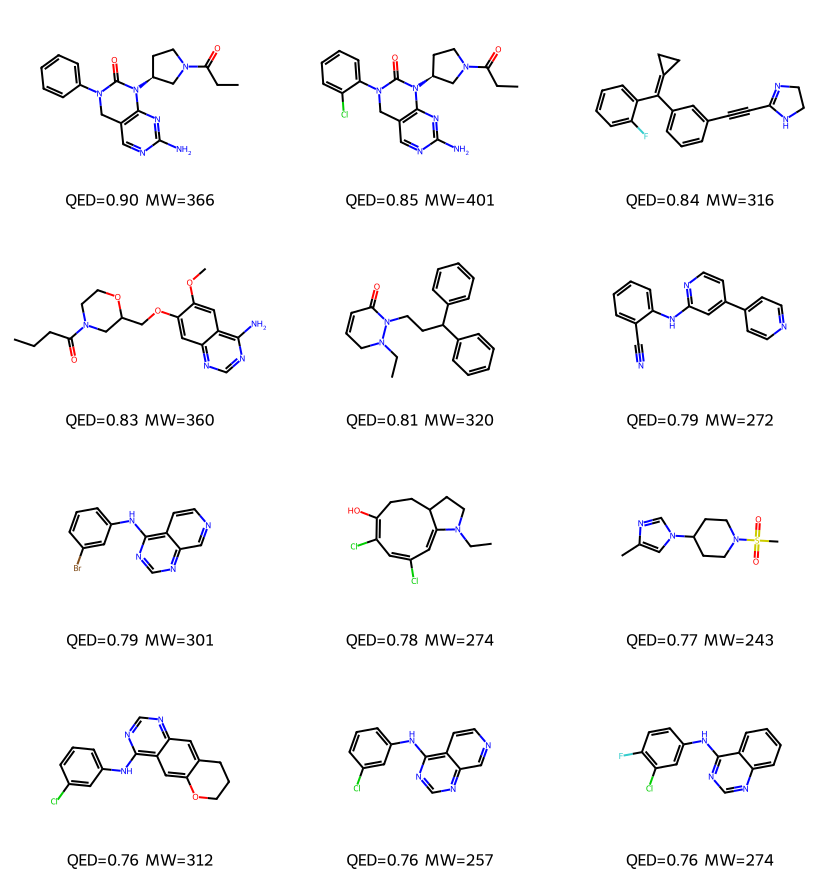

In [23]:
from rdkit.Chem import Draw

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH).sort_values('QED', ascending=False).reset_index(drop=True)
    mols = [Chem.MolFromSmiles(s) for s in df['smiles'][:12] if Chem.MolFromSmiles(s)]
    if mols:
        legends = [f"QED={q:.2f} MW={mw:.0f}" for q, mw in zip(df['QED'][:12], df['MW'][:12])]
        img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(280, 220), legends=legends)
        display(img)
else:
    print('No candidates yet')